In [1]:
!pip -q install lightgbm

import os, json, joblib
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from google.colab import files

os.makedirs("data/raw", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("Upload simulated_energy_data.csv and campus_rooms.csv")
uploaded = files.upload()
for name in uploaded:
    os.replace(name, f"data/raw/{name}")
print(os.listdir("data/raw"))

Upload simulated_energy_data.csv and campus_rooms.csv


Saving campus_rooms.csv to campus_rooms.csv
Saving simulated_energy_data.csv to simulated_energy_data.csv
['simulated_energy_data.csv', 'campus_rooms.csv']


In [2]:
DATA = "data/raw"
TARGET = "total_power_kw"

df = pd.read_csv(f"{DATA}/simulated_energy_data.csv", parse_dates=["timestamp"])
rooms = pd.read_csv(f"{DATA}/campus_rooms.csv")[["room_id", "capacity"]]
df = (df.merge(rooms, on="room_id")
        .sort_values(["room_id", "timestamp"])
        .reset_index(drop=True))

print(df.shape)
print(df.timestamp.min(), "->", df.timestamp.max())
print("Rooms:", df.room_id.nunique(), "| Buildings:", df.building_id.nunique())
print("Waste rows:", int(df.waste_event.sum()), f"({df.waste_event.mean()*100:.2f}%)")

# Campus-level hourly load, and the peak hour of each day
campus = (df.groupby("timestamp")
            .agg(campus_kw=(TARGET, "sum"),
                 temp=("outside_temp_c", "first"),
                 day_type=("day_type", "first"))
            .reset_index())
campus["date"] = campus.timestamp.dt.date
daily = campus.loc[campus.groupby("date").campus_kw.idxmax()]

print(daily.groupby("day_type").campus_kw.agg(["count", "mean", "max"]).round(1))
print("Peak hour on regular days:")
print(daily[daily.day_type == "regular"].timestamp.dt.hour.value_counts().sort_index())


(104832, 16)
2026-05-24 00:00:00 -> 2026-11-21 23:00:00
Rooms: 24 | Buildings: 3
Waste rows: 1146 (1.09%)
          count  mean   max
day_type                   
break        57  20.7  30.4
exam         25  45.5  57.8
holiday       4   9.7  11.9
regular      44  42.4  50.8
weekend      52   9.1  13.5
Peak hour on regular days:
timestamp
8      5
9      8
13     6
14    12
15    13
Name: count, dtype: int64


In [3]:
g = df.groupby("room_id")[TARGET]

df["lag_24"] = g.shift(24)            # same hour, yesterday
df["lag_168"] = g.shift(168)          # same hour, last week
df["lag_336"] = g.shift(336)          # same hour, two weeks ago
df["same_hour_mean_7d"] = sum(g.shift(24 * k) for k in range(1, 8)) / 7
df["mean_prev_24h"] = g.transform(lambda s: s.shift(24).rolling(24).mean())

df["scheduled"] = df["scheduled"].astype(int)     # timetable is known in advance
df["sched_lag_168"] = df.groupby("room_id")["scheduled"].shift(168)
df["hour"] = df.timestamp.dt.hour
df["dow"] = df.timestamp.dt.dayofweek

CATEGORICAL = ["room_id", "room_type", "building_id", "day_type"]
for c in CATEGORICAL:
    df[c] = df[c].astype("category")

FEATURES = [
    "hour", "dow", "scheduled", "outside_temp_c",
    "capacity", "room_id", "room_type", "building_id", "day_type",
    "lag_24", "lag_168", "lag_336", "same_hour_mean_7d", "mean_prev_24h", "sched_lag_168",
]

before = len(df)
df = df.dropna(subset=["lag_336"]).reset_index(drop=True)
print(f"Dropped {before - len(df)} rows (first 14 days have no 2-week history)")
print(len(FEATURES), "features")
df[FEATURES].head()

Dropped 8064 rows (first 14 days have no 2-week history)
15 features


,hour,dow,scheduled,outside_temp_c,capacity,room_id,room_type,building_id,day_type,lag_24,lag_168,lag_336,same_hour_mean_7d,mean_prev_24h,sched_lag_168
0,0,6,0,24.4,28,R01,Classroom,B01,exam,0.308,0.295,0.296,0.299000,0.314000,0.0
1,1,6,0,24.5,28,R01,Classroom,B01,exam,0.299,0.302,0.296,0.300429,0.314042,0.0
2,2,6,0,23.5,28,R01,Classroom,B01,exam,0.286,0.296,0.293,0.296000,0.313667,0.0
3,3,6,0,24.0,28,R01,Classroom,B01,exam,0.297,0.304,0.299,0.297857,0.313583,0.0
4,4,6,0,22.8,28,R01,Classroom,B01,exam,0.296,0.305,0.284,0.299000,0.313500,0.0


In [4]:
train = df[df.timestamp < "2026-10-18"]
valid = df[(df.timestamp >= "2026-10-18") & (df.timestamp < "2026-11-01")]
test  = df[df.timestamp >= "2026-11-01"]

for name, part in [("train", train), ("valid", valid), ("test", test)]:
    print(f"{name:5s} {len(part):>7,} rows  {part.timestamp.min()} -> {part.timestamp.max()}")

train  76,608 rows  2026-06-07 00:00:00 -> 2026-10-17 23:00:00
valid   8,064 rows  2026-10-18 00:00:00 -> 2026-10-31 23:00:00
test   12,096 rows  2026-11-01 00:00:00 -> 2026-11-21 23:00:00


In [5]:
model = lgb.LGBMRegressor(
    objective="huber",
    n_estimators=3000,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=50,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    random_state=42,
    verbose=-1,
)

model.fit(
    train[FEATURES], train[TARGET],
    eval_set=[(valid[FEATURES], valid[TARGET])],
    eval_metric="l1",
    callbacks=[lgb.early_stopping(100, verbose=False)],
)

print("best iteration:", model.best_iteration_)

best iteration: 218


In [6]:
def metrics(y, p):
    y, p = np.asarray(y), np.asarray(p)
    return {
        "MAE (kW)": np.abs(y - p).mean(),
        "RMSE (kW)": np.sqrt(((y - p) ** 2).mean()),
        "WAPE (%)": np.abs(y - p).sum() / y.sum() * 100,
    }

def at_level(frame, pred, level):
    f = frame[["timestamp", "building_id", TARGET]].copy()
    f["pred"] = np.asarray(pred)
    if level == "building":
        f = f.groupby(["timestamp", "building_id"], observed=True)[[TARGET, "pred"]].sum().reset_index()
    elif level == "campus":
        f = f.groupby("timestamp")[[TARGET, "pred"]].sum().reset_index()
    return metrics(f[TARGET], f["pred"])

predictions = {
    "LightGBM": model.predict(test[FEATURES]),
    "Baseline: yesterday": test["lag_24"].values,
    "Baseline: last week": test["lag_168"].values,
}

rows = []
for level in ["room", "building", "campus"]:
    for name, pred in predictions.items():
        rows.append({"level": level, "model": name, **at_level(test, pred, level)})

results = pd.DataFrame(rows).round(3)
results

,level,model,MAE (kW),RMSE (kW),WAPE (%)
0,room,LightGBM,0.045,0.146,7.403
1,room,Baseline: yesterday,0.303,0.802,50.300
2,room,Baseline: last week,0.065,0.217,10.711
3,building,LightGBM,0.220,0.437,4.563
4,building,Baseline: yesterday,1.579,3.482,32.725
5,building,Baseline: last week,0.345,0.707,7.152
6,campus,LightGBM,0.503,0.872,3.474
7,campus,Baseline: yesterday,3.998,9.514,27.622
8,campus,Baseline: last week,0.822,1.524,5.682


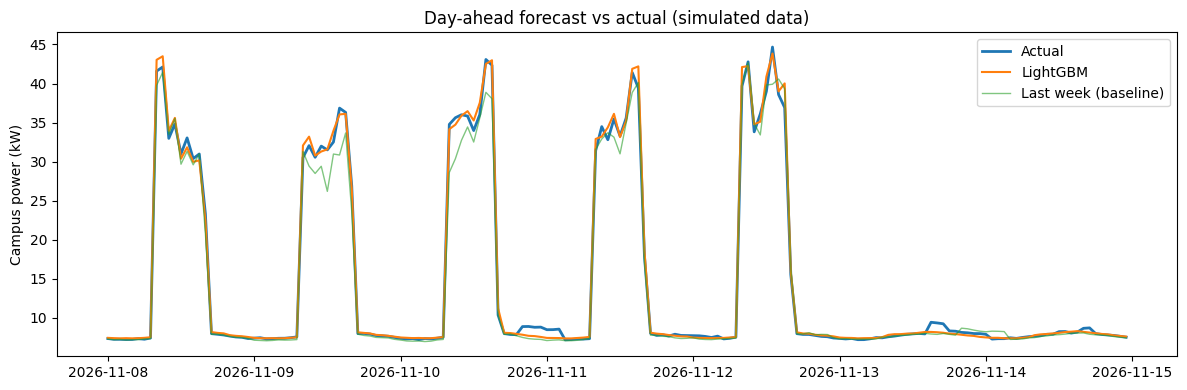

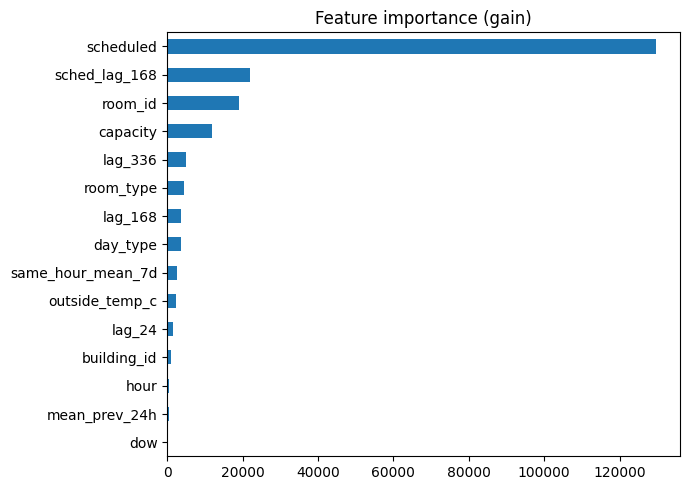

In [8]:

f = test[["timestamp", TARGET]].copy()
f["LightGBM"] = predictions["LightGBM"]
f["last week"] = test["lag_168"].values
campus_pred = f.groupby("timestamp").sum().reset_index()
week = campus_pred[(campus_pred.timestamp >= "2026-11-08") & (campus_pred.timestamp < "2026-11-15")]

plt.figure(figsize=(12, 4))
plt.plot(week.timestamp, week[TARGET], label="Actual", linewidth=2)
plt.plot(week.timestamp, week["LightGBM"], label="LightGBM", linewidth=1.5)
plt.plot(week.timestamp, week["last week"], label="Last week (baseline)", linewidth=1, alpha=0.6)
plt.ylabel("Campus power (kW)")
plt.title("Day-ahead forecast vs actual (simulated data)")
plt.legend()
plt.tight_layout()
plt.show()

# --- 2) Feature importance
imp = pd.Series(model.booster_.feature_importance("gain"), index=FEATURES).sort_values()
imp.plot.barh(figsize=(7, 5), title="Feature importance (gain)")
plt.tight_layout()
plt.show()

In [9]:
from sklearn.metrics import r2_score

def full_report(frame, pred, level):
    f = frame[["timestamp", "building_id", TARGET]].copy()
    f["pred"] = np.asarray(pred)
    if level == "building":
        f = f.groupby(["timestamp", "building_id"], observed=True)[[TARGET, "pred"]].sum().reset_index()
    elif level == "campus":
        f = f.groupby("timestamp")[[TARGET, "pred"]].sum().reset_index()
    y, p = f[TARGET].values, f["pred"].values
    wape = np.abs(y - p).sum() / y.sum() * 100
    return {"level": level, "R2": r2_score(y, p), "MAE (kW)": np.abs(y - p).mean(),
            "WAPE (%)": wape, "Accuracy (100-WAPE) %": 100 - wape}

pred = predictions["LightGBM"]
print(pd.DataFrame([full_report(test, pred, l) for l in ["room", "building", "campus"]]).round(3).to_string(index=False))

# Error by room type
t = test[["room_type", TARGET]].copy()
t["err"] = np.abs(test[TARGET].values - pred)
by_type = t.groupby("room_type", observed=True).agg(MAE=("err", "mean"), mean_kw=(TARGET, "mean"))
by_type["WAPE (%)"] = by_type.MAE / by_type.mean_kw * 100
print(by_type.round(3))

   level    R2  MAE (kW)  WAPE (%)  Accuracy (100-WAPE) %
    room 0.959     0.045     7.403                 92.597
building 0.989     0.220     4.563                 95.437
  campus 0.995     0.503     3.474                 96.526
                MAE  mean_kw  WAPE (%)
room_type                             
Classroom     0.042    0.550     7.612
Lab           0.056    0.820     6.845
Lecture Hall  0.065    0.851     7.641
Meeting Room  0.056    0.271    20.487
Office        0.029    0.531     5.442


In [10]:
joblib.dump({
    "model": model,
    "features": FEATURES,
    "categories": {c: list(df[c].cat.categories) for c in CATEGORICAL},
    "target": TARGET,
}, "models/forecast_lgbm.joblib")

results.to_csv("outputs/forecast_metrics.csv", index=False)

out = test[["timestamp", "building_id", "room_id", TARGET]].copy()
out["predicted_power_kw"] = predictions["LightGBM"].round(3)
out.to_csv("outputs/forecast_test_predictions.csv", index=False)

!zip -q -r forecast_outputs.zip models outputs
files.download("forecast_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>